# Do Waze users fall into natural behavior groups?

**Governing question.** Without looking at who churned, can we group Waze users by how they use the app, and do those groups turn out to have different churn rates? If they do, a product manager gets segments that come from behavior alone and can be targeted with different retention plans.

**Intended user.** A Waze product manager planning retention work, and the future PM-facing app, which will show each user's segment next to their churn risk.

**Why unsupervised.** Notebooks 02–05 *predicted* churn. This notebook asks a different question: what structure exists in usage on its own? The churn label is used only at the end, to **audit** the segments, never to form them.

**Evidence rules.** Development users only. The sealed test set stays closed. Figures use the shared seaborn style.

**Road map.** §1 data and preprocessing → §2 the mathematics of k-means and PCA → §3 verification of the student implementations → §4 PCA: what varies between users → §5 choosing the number of segments → §6 the segments → §7 auditing with churn → §8 stability → §9 limitations → §10 what a PM can do with this.

## 1. Data and preprocessing

We cluster on the ten usage measurements (`USAGE_COLUMNS`: sessions, drives, lifetime sessions, tenure, favorite-place navigations, km and minutes driven, active days, driving days). Device type is left out because it is not a behavior and showed no churn difference.

Two preprocessing choices matter for distance-based methods:

- **Log transform (`log1p`).** Several counts have long right tails (notebook 02), so a few extreme users would dominate squared distances. `log1p(x) = log(1 + x)` compresses the tail and handles zeros.
- **Standardization.** After the log, each feature is scaled to mean 0 and standard deviation 1, so no feature dominates just because of its units.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans as TrustedKMeans
from sklearn.decomposition import PCA as TrustedPCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from dsm_project.algorithms import PCA, KMeans
from dsm_project.config import load_config
from dsm_project.data.waze import USAGE_COLUMNS, WazeChurnAdapter
from dsm_project.experiments import split_supervised_task
from dsm_project.features import engineer_features
from dsm_project.segments import THREE_SEGMENT_NAMES, UserSegmenter
from dsm_project.visualization import plot_rate_by_group, rate_by_group, set_theme

set_theme()
config = load_config(Path("configs/waze.toml"))
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
usage = dev_x[list(USAGE_COLUMNS)]
standardized = StandardScaler().fit_transform(np.log1p(usage))
print(f"development users: {len(usage):,} | clustering on {standardized.shape[1]} features")

development users: 10,724 | clustering on 10 features


## 2. The mathematics

### 2.1 k-means

Given standardized users $x_1, \dots, x_n \in \mathbb{R}^{10}$ and a number of segments $k$, k-means looks for centers $\mu_1, \dots, \mu_k$ minimizing the **inertia**, the total squared distance from each user to their nearest center:

$$
J(\mu_1,\dots,\mu_k) = \sum_{i=1}^{n} \min_{j} \lVert x_i - \mu_j \rVert^2 .
$$

**Lloyd's algorithm** alternates two steps, each of which can only lower $J$:

1. *Assign:* put each user in the segment of its nearest center.
2. *Update:* move each center to the mean of its users. The mean minimizes the sum of squared distances to a set of points.

It stops when no user changes segment. Because it only finds a *local* minimum, we start it from **k-means++** centers, where each new starting center is drawn with probability proportional to its squared distance from the centers already chosen. We restart 10 times and keep the run with the lowest inertia. One iteration costs $O(nkd)$.

### 2.2 PCA

PCA finds the directions along which users differ most. With centered data $X_c$ and its singular value decomposition $X_c = U S V^\top$, the rows of $V^\top$ are the **principal directions** (loadings), $X_c V$ gives each user's coordinates (scores), and component $j$ explains variance $s_j^2/(n-1)$. The first two components give the best two-dimensional picture of the data in squared error, which we use to *visualize* the segments.

### 2.3 Judging clusters without labels

With no correct answer to compare against, we use three kinds of evidence:

- **Inertia** always falls as $k$ grows. We look for an "elbow" where adding segments stops helping much.
- **Silhouette.** For user $i$, with $a_i$ the mean distance to its own segment and $b_i$ the mean distance to the nearest other segment, $s_i = (b_i - a_i)/\max(a_i, b_i) \in [-1, 1]$. Values near 1 mean tight, well-separated segments; values near 0 mean users sit between segments.
- **Stability.** If we refit with a different random start, or on a resampled set of users, do we get the same segments? We measure agreement with the **adjusted Rand index** (ARI): 1 for identical groupings, about 0 for chance agreement.

## 3. Student implementation and verification

| Component | Package location | Key evidence |
| --- | --- | --- |
| `KMeans` | `student/unsupervised.py` | hand-computable two-group case (inertia exactly 4); inertia with $k = 1$ equals the total sum of squares; k-means++ starts cover all three test blobs in about 82% of seeds versus 26% for random starts; identical result to scikit-learn's `KMeans` from the same starting centers |
| `PCA` | `student/unsupervised.py` | points on a line give one component with 100% of the variance; components orthonormal; reconstruction error equals the variance of the dropped components; identical to scikit-learn's `PCA` |
| `UserSegmenter` | `segments.py` | names segments from their centers, so names do not depend on cluster numbering; recovers constructed groups |

Live check on the Waze development users:

In [2]:
student_pca = PCA().fit(standardized)
trusted_pca = TrustedPCA().fit(standardized)
print("PCA: max |component difference|",
      f"{np.abs(student_pca.components_ - trusted_pca.components_).max():.1e}")

start = standardized[np.random.default_rng(0).choice(len(standardized), 3, replace=False)]
student_km = KMeans(3, init=start, tol=0).fit(standardized)
trusted_km = TrustedKMeans(3, init=start, n_init=1, tol=0, algorithm="lloyd").fit(standardized)
print("k-means (same start): identical segments =",
      np.array_equal(student_km.labels_, trusted_km.labels_),
      f"| inertia {student_km.inertia_:.1f} vs {trusted_km.inertia_:.1f}")

PCA: max |component difference| 1.0e-13
k-means (same start): identical segments = True | inertia 82006.7 vs 82006.7


Both student implementations reproduce scikit-learn on the real data: identical principal components up to rounding, and the same segments from the same starting centers.

## 4. PCA: what varies between users?

Before clustering, PCA shows how much structure there is to find. If a few components explained most of the variance, users would lie near a low-dimensional surface where groups are easy to see.

first two components explain 44% of the variance


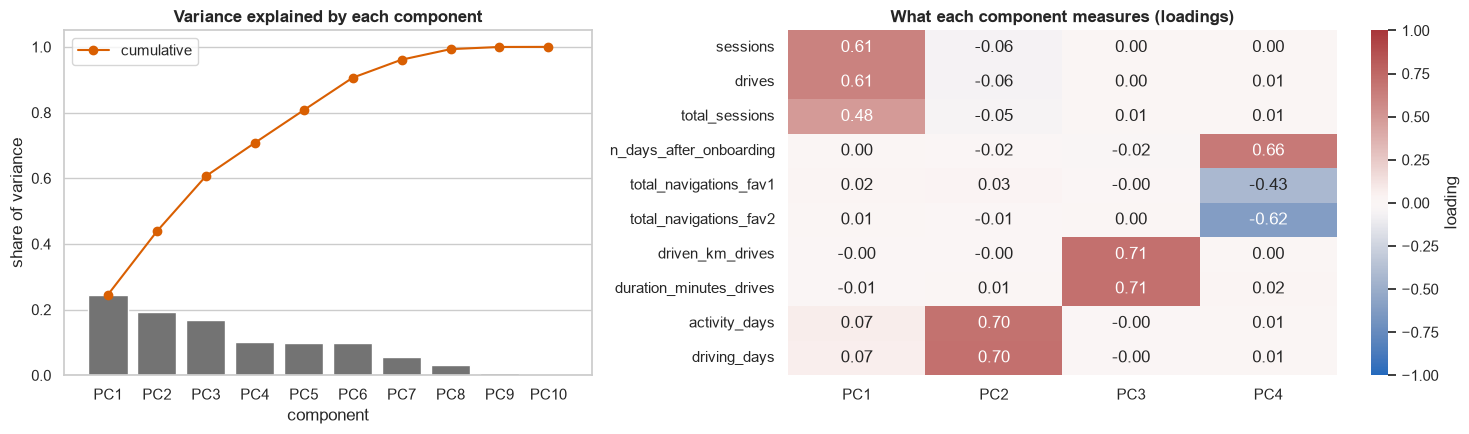

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ratio = pd.DataFrame({"component": [f"PC{i}" for i in range(1, 11)],
                      "share of variance": student_pca.explained_variance_ratio_})
sns.barplot(data=ratio, x="component", y="share of variance", color="0.45", ax=axes[0])
axes[0].plot(range(10), ratio["share of variance"].cumsum(), "o-", color="#d95f02",
             label="cumulative")
axes[0].set(title="Variance explained by each component")
axes[0].legend()

loadings = pd.DataFrame(student_pca.components_[:4].T, index=list(USAGE_COLUMNS),
                        columns=["PC1", "PC2", "PC3", "PC4"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            ax=axes[1], cbar_kws={"label": "loading"})
axes[1].set(title="What each component measures (loadings)")
plt.tight_layout()
print("first two components explain",
      f"{student_pca.explained_variance_ratio_[:2].sum():.0%} of the variance")

**Insights.**

- **There is no single dominant direction.** The first component explains about a quarter of the variance and the first two together about 44%, so users do not lie near a simple low-dimensional shape.
- **Each component is one kind of usage.** PC1 is *volume* (sessions, drives, lifetime sessions), PC2 is *frequency* (active days and driving days), and PC3 is *distance* (km and minutes driven). Tenure and favorite-place use only appear from PC4 on, separate from volume, frequency, and distance. Such clean separation is plausibly an artifact of how the synthetic data were generated.
- Frequency (PC2) is the direction that every earlier notebook linked to churn. We will see whether the segments line up with it.

## 5. Choosing the number of segments

We fit the student k-means for $k = 2, \dots, 8$ and record inertia, silhouette (on a random sample of 3,000 users, to keep it fast), and stability against three other random seeds.

,inertia,silhouette,stability (ARI across seeds)
k,,,
2,90152.052,0.156,0.993
3,78029.165,0.165,0.999
4,71336.045,0.138,0.980
5,67197.552,0.141,0.931
6,63566.347,0.138,0.970
7,60652.982,0.126,0.588
8,58269.853,0.122,0.622


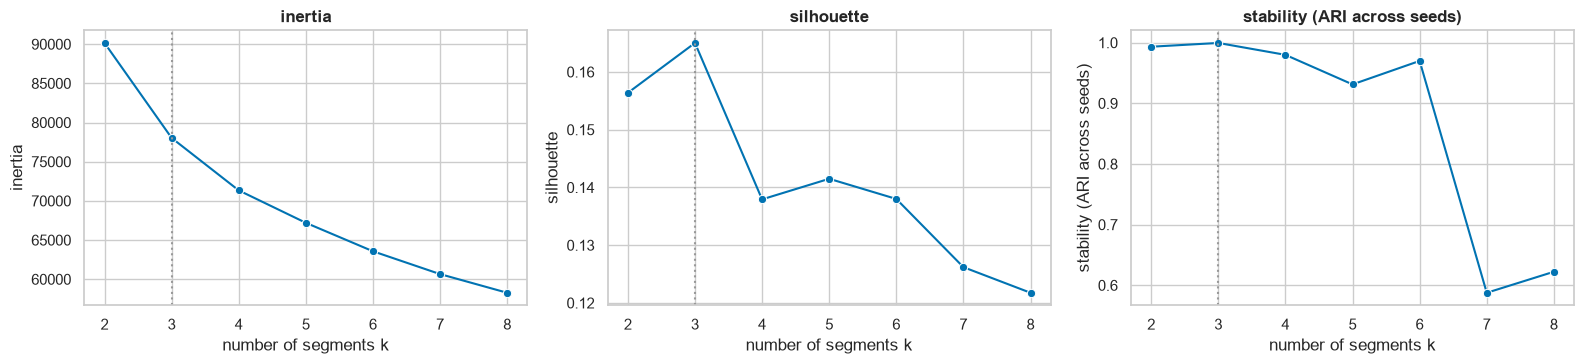

In [4]:
sample = np.random.default_rng(0).choice(len(standardized), 3000, replace=False)
rows = []
for k in range(2, 9):
    model = KMeans(k, random_state=0).fit(standardized)
    other_runs = [KMeans(k, random_state=seed).fit(standardized).labels_ for seed in (1, 2, 3)]
    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(standardized[sample], model.labels_[sample]),
        "stability (ARI across seeds)": np.mean(
            [adjusted_rand_score(model.labels_, other) for other in other_runs]),
    })
choice = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, column in zip(axes, choice.columns, strict=True):
    sns.lineplot(x=choice.index, y=choice[column], marker="o", ax=ax)
    ax.axvline(3, color="0.6", linestyle=":")
    ax.set(xlabel="number of segments k", title=column)
plt.tight_layout()
display(choice.round(3))

**Reading the evidence.**

- **Inertia** has no sharp elbow, consistent with the PCA finding that the data form one continuous cloud.
- **Silhouette is low for every $k$** (about 0.12–0.17) and highest at **$k = 3$**. The segments are real but not sharply separated: they divide a continuum, like "light, medium, heavy" customers, rather than discovering distinct species.
- **Stability:** $k = 3$ is almost perfectly reproducible across seeds (ARI ≈ 1.0), stability stays high up to $k = 6$, and from $k = 7$ the grouping changes from seed to seed.

**Choice, fixed before looking at churn:** $k = 3$, with the best silhouette, near-perfect stability, and few enough segments for a PM to act on.

## 6. The three segments

`UserSegmenter` fits this model and names the segments from their centers. The profile shows each segment's *median* usage in original units, plus how often its users carry the behavior flags from notebook 05.

segment,Occasional users,Steady light users,Steady heavy users
sessions,55.00,15.00,95.00
drives,47.00,14.00,80.00
total_sessions,154.58,74.29,211.30
n_days_after_onboarding,1818.00,1727.00,1744.00
total_navigations_fav1,67.00,70.00,74.00
total_navigations_fav2,8.00,7.00,9.00
driven_km_drives,3534.04,3541.60,3468.65
duration_minutes_drives,1479.57,1506.31,1468.58
activity_days,3.00,18.00,19.00
driving_days,1.00,14.00,15.00


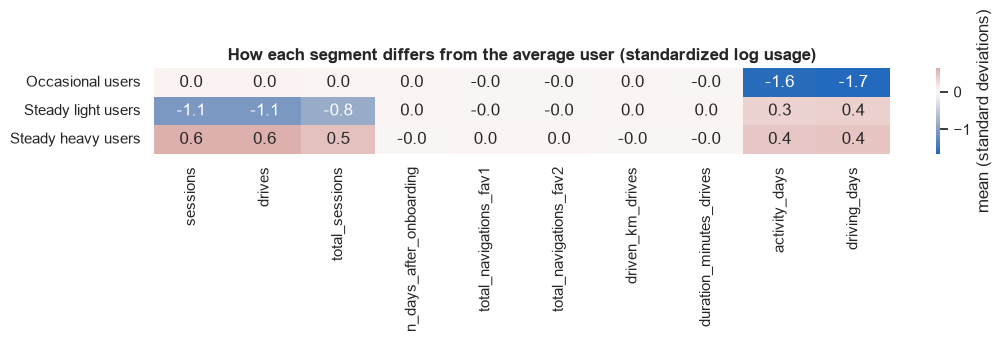

In [5]:
segmenter = UserSegmenter(3, random_state=438).fit(dev_x)
segment = segmenter.predict(dev_x)
flags = engineer_features(dev_x)[["professional_driver", "low_driving_frequency", "heavy_driver"]]
profile = pd.concat([
    segmenter.profile_.T,
    flags.groupby(segment).mean().T.rename(index=lambda name: f"share {name.replace('_', ' ')}"),
    segment.value_counts().rename("users").to_frame().T,
])[list(THREE_SEGMENT_NAMES)]
display(profile.round(2))

z_scores = pd.DataFrame(standardized, columns=list(USAGE_COLUMNS)).groupby(segment.to_numpy()).mean()
fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(z_scores.loc[list(THREE_SEGMENT_NAMES)], annot=True, fmt=".1f", cmap="vlag",
            center=0, ax=ax, cbar_kws={"label": "mean (standard deviations)"})
ax.set(title="How each segment differs from the average user (standardized log usage)",
       ylabel="")
plt.tight_layout()

**Insights.**

- **Occasional users** (about 20% of users) open Waze on a median of only 3 days a month and drive on 1. Almost all of them (98%) are low-frequency drivers. Yet they log a median of 55 sessions, more than steady light users, packed into those few days. Their use is *bursty*, the short-term heavy pattern from my earlier analysis.
- **Steady light users** (about 30%) are active on most days but log few sessions: regular, low-volume users.
- **Steady heavy users** (about 50%) are just as regular but log about six times as many sessions. About a third of them are professional drivers.
- **What does *not* separate users:** tenure, distance and minutes driven, and favorite-place use look almost identical across segments. The segments are about *how often* and *how much* people use Waze, not how far they drive.

The PCA picture shows how the segments sit in the two main directions of variation (a random sample of 3,000 users, for readability):

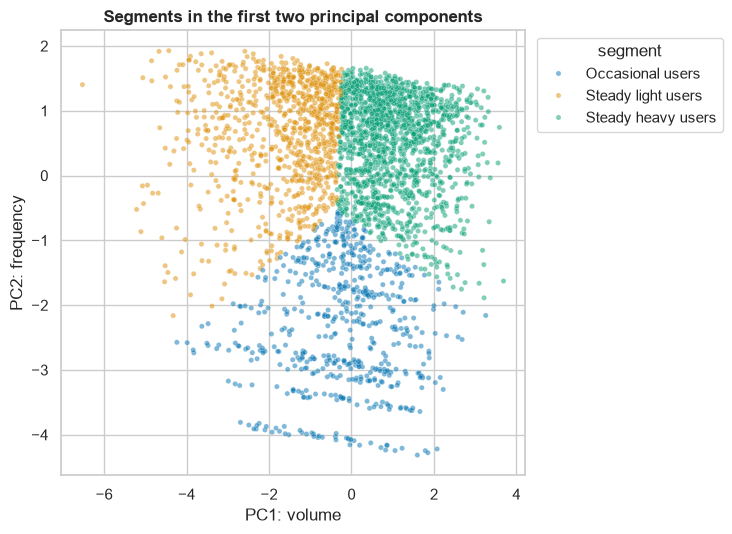

In [6]:
scores = student_pca.transform(standardized)[:, :2]
picture = pd.DataFrame({"PC1: volume": scores[sample, 0], "PC2: frequency": scores[sample, 1],
                        "segment": segment.to_numpy()[sample]})
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=picture, x="PC1: volume", y="PC2: frequency", hue="segment",
                hue_order=list(THREE_SEGMENT_NAMES), alpha=0.5, s=14, ax=ax)
ax.set(title="Segments in the first two principal components")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

The segments split mainly along **frequency** (vertical) and **volume** (horizontal), with no empty space between them. This matches the low silhouette: the boundaries are drawn through a continuous cloud of users.

## 7. Auditing the segments with churn

Only now do we look at the churn label: do segments formed from behavior alone differ in churn?

,users,churned,rate,ci_low,ci_high,share of users,share of churners
Occasional users,2120,790,0.373,0.352,0.393,0.198,0.415
Steady light users,3217,407,0.127,0.115,0.138,0.300,0.214
Steady heavy users,5387,705,0.131,0.122,0.140,0.502,0.371


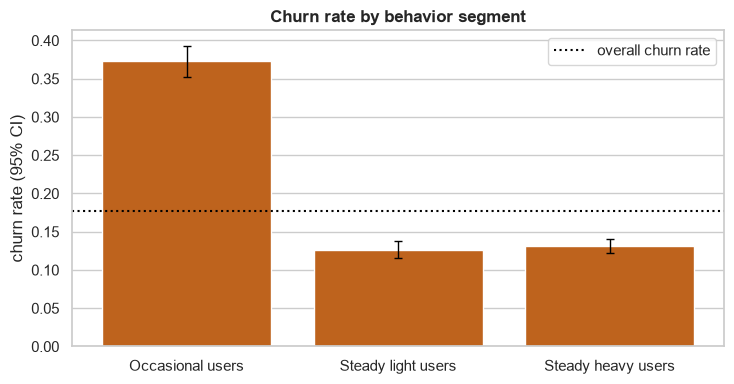

In [7]:
overall = dev_y.mean()
table = rate_by_group(dev_y, pd.Series(pd.Categorical(segment, categories=list(THREE_SEGMENT_NAMES)),
                                       index=dev_y.index))
table["share of users"] = table["users"] / table["users"].sum()
table["share of churners"] = table["churned"] / table["churned"].sum()

fig, ax = plt.subplots(figsize=(7.5, 4))
plot_rate_by_group(table, overall_rate=overall, ax=ax, title="Churn rate by behavior segment")
plt.tight_layout()
display(table.round(3))

**Insights.**

- **Occasional users churn at about 37%**, nearly three times the rate of either steady segment (about 13%), and the 95% intervals are far apart. This segment is about a fifth of users but **about 40% of all churners**.
- **Steady light and steady heavy users churn at the same rate** (about 13%), even though heavy users log about six times as many sessions. Volume of use makes no difference to retention once someone uses Waze regularly.

**Main takeaway: frequency, not volume, separates loyal users from churners.** Segments formed without the churn label reach the same conclusion as the supervised models and my earlier analysis.

## 8. Stability on resampled users

A segment definition a PM relies on should not change if we had observed a slightly different set of users. We refit the segmenter on 10 bootstrap resamples of the development users, assign every user with each refit, and compare to the original segments.

In [8]:
rng = np.random.default_rng(1)
agreement = []
for _ in range(10):
    resample = rng.integers(0, len(dev_x), len(dev_x))
    refit = UserSegmenter(3, random_state=438).fit(dev_x.iloc[resample])
    reassigned = refit.predict(dev_x)
    agreement.append({"ARI vs original": adjusted_rand_score(segment, reassigned),
                      "same named segment": float((reassigned == segment).mean())})
agreement = pd.DataFrame(agreement)
display(agreement.describe().loc[["mean", "min", "max"]].round(3))

,ARI vs original,same named segment
mean,0.967,0.989
min,0.947,0.982
max,0.983,0.994


The segments are stable. Across 10 resamples the ARI against the original segments stays between about 0.95 and 0.98, and because names come from the segment centers, 98–99% of users keep the *same named segment*. A PM can treat these three groups as a dependable definition.

## 9. Limitations

- **Weak cluster structure.** Silhouette ≈ 0.17: the segments divide a continuum rather than reveal distinct populations. Users near a boundary could reasonably fall in either neighboring segment.
- **One month of behavior.** Segments describe this month's usage. A user can move between segments from month to month, and this dataset cannot show those transitions.
- **Synthetic data.** Tenure, distance, and favorite-place use vary independently of everything else, which is unusual for real usage. These features may matter for real users even though they do not separate segments here.
- **Not causal.** Occasional users churn more, but making someone use Waze more often would not necessarily keep them. That needs an experiment.

## 10. What a PM can do with this

| Segment | Share of users | Churn | Suggested focus |
| --- | --- | --- | --- |
| Occasional users | ~20% | ~37% | Build the habit: they use Waze in bursts, so commute reminders, saved routes, and re-engagement after inactive weeks |
| Steady light users | ~30% | ~13% | Keep it easy: protect the core navigation experience they rely on |
| Steady heavy users | ~50% | ~13% | Protect power users: about a third are professional drivers, sensitive to ETA accuracy and route quality |

**Decision.**

- Adopt the three named segments as the project's standard user grouping. `UserSegmenter` is in the package and tested, ready for the PM-facing app, where each scored user can be shown with their segment.
- Segments complement the churn model rather than replace it. Within the occasional segment, the risk score still ranks who is most likely to leave.

**Next steps.** Linear SVM and a small neural network as further churn models, then model selection on the sealed test set, then the product (API and Streamlit app) using both the risk score and the segment.